# Workflow Engine — przewodnik po paczce

Notebook prowadzi przez główne publiczne API: komponenty Extract–Transform–Load, batch processing, dekoratory, zadania, graf zależności, wykonanie synchroniczne i asynchroniczne oraz raportowanie statusów i czasu.

Uruchamiaj komórki po kolei. Wszystkie dane są przykładowe; SQLite działa w pamięci, a pliki JSON trafiają do katalogu tymczasowego.

## 1. Importy i interfejsy bazowe

Gotowe komponenty są dostępne z `workflow_engine`, a interfejsy bazowe z `workflow_engine.base`. Prywatne moduły implementacyjne nie są potrzebne przy zwykłym korzystaniu z paczki.

In [11]:
import asyncio
import json
import logging
import sqlite3
import tempfile
from collections.abc import Iterable, Iterator
from pathlib import Path

from workflow_engine import (
    CleanRecordsTransformer,
    CsvExtractor,
    FilterRecordsTransformer,
    InMemoryExtractor,
    JsonLoader,
    ListLoader,
    Pipeline,
    SelectColumnsTransformer,
    SqlExtractor,
    SqliteLoader,
    retry,
    task,
    track_latency,
)
from workflow_engine.base import BaseExtractor, BaseLoader, BaseTransformer, Batch, Record

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
logging.getLogger("workflow_engine.pipeline").setLevel(logging.INFO)
print("Importy gotowe")

Importy gotowe


### Własny komponent i interfejs bazowy

Komponenty można rozszerzać przez klasy bazowe. Poniżej własny transformer implementuje kontrakt `BaseTransformer`: przyjmuje `Batch` i zwraca `Batch`.

In [12]:
class AddSourceTransformer(BaseTransformer):
    def transform(self, batch: Batch) -> Batch:
        return [{**record, "source": "notebook"} for record in batch]

AddSourceTransformer().transform([{"name": "Ada"}])

[{'name': 'Ada', 'source': 'notebook'}]

### Rysowanie grafu jako obrazu

Poniższy helper renderuje zależności jako SVG bez dodatkowej biblioteki do wykresów. Kolor węzła pokazuje status zadania: nieuruchomione, działające, zakończone, nieudane lub pominięte.

In [13]:
from html import escape
from IPython.display import SVG, display

def display_pipeline_graph(pipeline: Pipeline) -> None:
    dependencies = pipeline.dependency_graph()
    if not dependencies:
        display(SVG('<svg xmlns="http://www.w3.org/2000/svg" width="240" height="50"><text x="12" y="30">Brak zadań</text></svg>'))
        return

    levels: dict[str, int] = {}
    columns: dict[int, list[str]] = {}
    for name, parents in dependencies.items():
        level = 0 if not parents else 1 + max(levels[parent] for parent in parents)
        levels[name] = level
        columns.setdefault(level, []).append(name)

    node_width, node_height = 190, 56
    column_gap, row_gap, margin = 105, 34, 36
    max_rows = max(map(len, columns.values()))
    width = 2 * margin + len(columns) * node_width + (len(columns) - 1) * column_gap
    height = 2 * margin + max_rows * node_height + (max_rows - 1) * row_gap
    positions: dict[str, tuple[int, int]] = {}
    for level, names in columns.items():
        vertical_offset = (max_rows - len(names)) * (node_height + row_gap) // 2
        for index, name in enumerate(names):
            positions[name] = (
                margin + level * (node_width + column_gap),
                margin + vertical_offset + index * (node_height + row_gap),
            )

    statuses = (
        {item.name: item.status for item in pipeline.last_report.tasks}
        if pipeline.last_report is not None
        else {}
    )
    colors = {
        "added": "#e0e7ff",
        "succeeded": "#dcfce7",
        "running": "#fef3c7",
        "failed": "#fee2e2",
        "skipped": "#e2e8f0",
    }

    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<defs><marker id="arrow" markerWidth="10" markerHeight="8" refX="9" refY="4" orient="auto"><path d="M0,0 L10,4 L0,8 z" fill="#64748b"/></marker></defs>',
        '<rect width="100%" height="100%" rx="12" fill="#ffffff"/>',
    ]
    for child, parents in dependencies.items():
        child_x, child_y = positions[child]
        for parent in parents:
            parent_x, parent_y = positions[parent]
            start_x = parent_x + node_width
            end_x = child_x
            middle_x = (start_x + end_x) // 2
            start_y = parent_y + node_height // 2
            end_y = child_y + node_height // 2
            parts.append(
                f'<path d="M {start_x} {start_y} C {middle_x} {start_y}, {middle_x} {end_y}, {end_x} {end_y}" fill="none" stroke="#64748b" stroke-width="2" marker-end="url(#arrow)"/>'
            )

    for name, (x, y) in positions.items():
        status = statuses.get(name, "added")
        fill = colors[status]
        parts.extend([
            f'<rect x="{x}" y="{y}" width="{node_width}" height="{node_height}" rx="10" fill="{fill}" stroke="#475569" stroke-width="1.5"/>',
            f'<text x="{x + node_width // 2}" y="{y + 24}" text-anchor="middle" font-family="sans-serif" font-size="14" font-weight="600" fill="#0f172a">{escape(name)}</text>',
            f'<text x="{x + node_width // 2}" y="{y + 43}" text-anchor="middle" font-family="sans-serif" font-size="12" fill="#334155">{escape(status)}</text>',
        ])
    parts.append("</svg>")
    display(SVG("".join(parts)))

## 2. Batch processing i komponenty Extract–Transform–Load

`InMemoryExtractor` dzieli rekordy na partie o maksymalnym rozmiarze określonym przez `batch_size`. Każdy batch jest listą rekordów (mapowań).

In [14]:
records: list[Record] = [
    {"name": " Ada ", "role": " engineer ", "active": True},
    {"name": "Grace", "role": " scientist ", "active": True},
    {"name": "Alan", "role": " mathematician ", "active": False},
]

extractor = InMemoryExtractor(records)
batches: list[Batch] = list(extractor.extract(batch_size=2))
print(f"Liczba batchy: {len(batches)}")
for index, batch in enumerate(batches, start=1):
    print(f"Batch {index}: {batch}")

Liczba batchy: 2
Batch 1: [{'name': ' Ada ', 'role': ' engineer ', 'active': True}, {'name': 'Grace', 'role': ' scientist ', 'active': True}]
Batch 2: [{'name': 'Alan', 'role': ' mathematician ', 'active': False}]


Transformatory przyjmują jeden batch i zwracają batch. Można je łączyć: najpierw normalizujemy tekst, potem filtrujemy rekordy, a na końcu wybieramy potrzebne kolumny.

In [15]:
cleaner = CleanRecordsTransformer()
active_only = FilterRecordsTransformer(lambda record: record["active"] is True)
select_name_and_role = SelectColumnsTransformer(["name", "role"])

cleaned_batches = [cleaner.transform(batch) for batch in batches]
filtered_batches = [active_only.transform(batch) for batch in cleaned_batches]
selected_batches = [
    select_name_and_role.transform(batch) for batch in filtered_batches
]
selected_batches

[[{'name': 'Ada', 'role': 'engineer'}, {'name': 'Grace', 'role': 'scientist'}],
 []]

`ListLoader` zbiera rekordy ze wszystkich batchy do jednej listy. `JsonLoader` zapisuje je do pliku JSON; tutaj używamy katalogu tymczasowego, który usunie się po wyjściu z bloku.

In [16]:
loaded_records = ListLoader().load(selected_batches)
print("Wynik ListLoader:", loaded_records)

with tempfile.TemporaryDirectory() as temporary_directory:
    json_path = Path(temporary_directory) / "records.json"
    written_path = JsonLoader(json_path).load(selected_batches)
    print("Zapisano:", written_path.name)
    print("Odczyt JSON:", json.loads(written_path.read_text(encoding="utf-8")))

Wynik ListLoader: [{'name': 'Ada', 'role': 'engineer'}, {'name': 'Grace', 'role': 'scientist'}]
Zapisano: records.json
Odczyt JSON: [{'name': 'Ada', 'role': 'engineer'}, {'name': 'Grace', 'role': 'scientist'}]


## Przykład: Pipeline ETL batchowego i treningu modelu

To osobny DAG z czterema zadaniami: **1. extract** zwraca iterator batchy; **2. transform** przetwarza je leniwie i zwraca iterator batchy; **3. load** konsumuje iterator i zapisuje JSON, po czym zwraca ścieżkę; **4. train** dostaje ścieżkę i czyta rekordy z pliku strumieniowo.

Pipeline nie zgaduje, co jest batchem ani nie dzieli danych sam — kod zadania definiuje kontrakt wejścia i wyjścia. `depends_on` ustawia kolejność i przekazuje wynik (tu: iterator lub ścieżkę) następnemu zadaniu. Żaden etap nie buduje listy wszystkich wierszy. Model regresji liniowej liczy statystyki przyrostowo, czystym Pythonem, bez dodatkowej biblioteki ML.

In [17]:
model_temp = tempfile.TemporaryDirectory()
training_csv_path = Path(model_temp.name) / "study_data.csv"
training_csv_path.write_text(
    "hours_studied,exam_score\n1,51\n2,55\n3,60\n4,67\n5,69\n6,76\n",
    encoding="utf-8",
)

# Krok 1 — zwracamy iterator: rekordy są czytane po jednym batchu.
@task(name="etl_extract")
def extract_training_data() -> Iterable[Batch]:
    print("Krok 1 — extract: start odczytu CSV w batchach po 2 rekordy")
    return CsvExtractor(training_csv_path).extract(batch_size=2)

In [18]:
class NumericTrainingTransformer(BaseTransformer):
    def transform(self, batch: Batch) -> Batch:
        return [
            {
                "hours_studied": float(record["hours_studied"]),
                "exam_score": float(record["exam_score"]),
            }
            for record in batch
        ]

# Krok 2 — wejściem jest wynik etl_extract, nadal podzielony na batche.
@task(name="etl_transform", depends_on=("etl_extract",))
def transform_training_data(batches: Iterable[Batch]) -> Iterator[Batch]:
    clean_training = CleanRecordsTransformer(drop_empty_values=True)
    valid_training = FilterRecordsTransformer(
        lambda record: bool(record.get("hours_studied"))
        and bool(record.get("exam_score")),
    )
    numeric_training = NumericTrainingTransformer()
    for batch in batches:
        cleaned = clean_training.transform(batch)
        valid = valid_training.transform(cleaned)
        yield numeric_training.transform(valid)


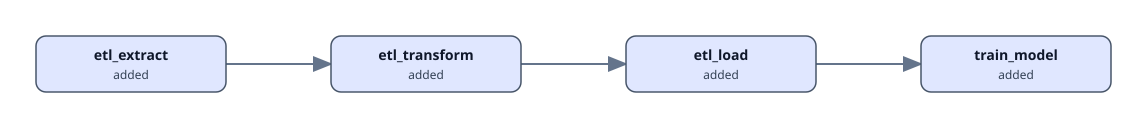

In [19]:
# Krok 3 — load zapisuje dane i zwraca ścieżkę jako wynik zadania.
training_json_path = Path(model_temp.name) / "training_data.json"

@task(name="etl_load", depends_on=("etl_transform",))
def load_training_data(batches: Iterable[Batch]) -> str:
    written_path = JsonLoader(training_json_path).load(batches)
    print(f"Krok 3 — load: zapisano {written_path.name}")
    return str(written_path)

def iter_json_array_records(path: Path, chunk_size: int = 64) -> Iterator[Record]:
    if chunk_size < 1:
        raise ValueError("chunk_size must be positive")

    decoder = json.JSONDecoder()
    buffer = ""
    position = 0
    started = False
    expecting_value = True
    after_comma = False

    with path.open("r", encoding="utf-8") as file:
        while True:
            chunk = file.read(chunk_size)
            eof = not chunk
            buffer += chunk

            while True:
                while position < len(buffer) and buffer[position].isspace():
                    position += 1

                if not started:
                    if position == len(buffer):
                        break
                    if buffer[position] != "[":
                        raise ValueError("expected a JSON array")
                    started = True
                    position += 1
                    continue

                if position == len(buffer):
                    break

                if buffer[position] == "]":
                    if after_comma:
                        raise ValueError("unexpected trailing comma in JSON array")
                    if buffer[position + 1 :].strip():
                        raise ValueError("unexpected content after JSON array")
                    while True:
                        trailing = file.read(chunk_size)
                        if not trailing:
                            return
                        if trailing.strip():
                            raise ValueError("unexpected content after JSON array")

                if not expecting_value:
                    if buffer[position] != ",":
                        raise ValueError("expected a comma between JSON records")
                    position += 1
                    expecting_value = True
                    after_comma = True
                    continue

                try:
                    value, next_position = decoder.raw_decode(buffer, position)
                except json.JSONDecodeError:
                    if eof:
                        raise
                    break
                if not isinstance(value, dict):
                    raise TypeError("expected each JSON array item to be an object")
                yield value
                position = next_position
                expecting_value = False
                after_comma = False

            if eof:
                raise ValueError("incomplete JSON array")
            buffer = buffer[position:]
            position = 0

# Krok 4 — train dostaje ścieżkę z etl_load i czyta rekordy inkrementalnie.
@task(name="train_model", depends_on=("etl_load",))
def train_linear_model(json_path: str) -> dict[str, object]:
    count = 0
    sum_x = sum_y = sum_x_squared = sum_xy = 0.0
    for row in iter_json_array_records(Path(json_path), chunk_size=64):
        x = float(row["hours_studied"])
        y = float(row["exam_score"])
        count += 1
        sum_x += x
        sum_y += y
        sum_x_squared += x * x
        sum_xy += x * y
    denominator = count * sum_x_squared - sum_x * sum_x
    if count < 2 or denominator == 0:
        raise ValueError("model needs at least two distinct feature values")
    slope = (count * sum_xy - sum_x * sum_y) / denominator
    intercept = (sum_y - slope * sum_x) / count
    prediction = slope * 7.0 + intercept
    print(f"Krok 4 — train: model dopasowany strumieniowo na {count} rekordach")
    return {
        "slope": slope,
        "intercept": intercept,
        "training_rows": count,
        "prediction_for_7_hours": prediction,
    }

model_pipeline = Pipeline()
model_pipeline.add(train_linear_model)
model_pipeline.add(load_training_data)
model_pipeline.add(transform_training_data)
model_pipeline.add(extract_training_data)
display_pipeline_graph(model_pipeline)

INFO Starting task etl_extract
INFO Finished task etl_extract in 0.000 seconds
INFO Starting task etl_transform
INFO Finished task etl_transform in 0.000 seconds
INFO Starting task etl_load
INFO Finished task etl_load in 0.013 seconds
INFO Starting task train_model


Krok 1 — extract: start odczytu CSV w batchach po 2 rekordy
Krok 3 — load: zapisano training_data.json
Krok 4 — train: model dopasowany strumieniowo na 6 rekordach


INFO Finished task train_model in 0.010 seconds


Wytrenowany model: {'slope': 4.9714285714285715, 'intercept': 45.6, 'training_rows': 6, 'prediction_for_7_hours': 80.4}
etl_extract: succeeded
etl_transform: succeeded
etl_load: succeeded
train_model: succeeded


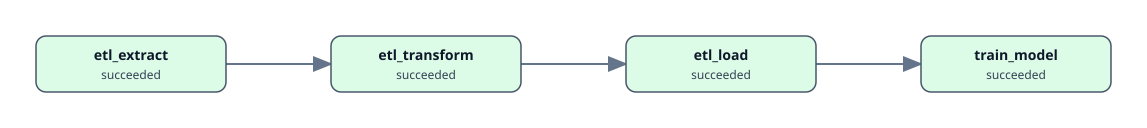

In [20]:
model_results = model_pipeline.run()
trained_model = model_results["train_model"]
print("Wytrenowany model:", trained_model)

for job_report in model_pipeline.last_report.tasks:
    print(f"{job_report.name}: {job_report.status}")

# Po wykonaniu pipeline'u graf pokazuje status każdego zadania.
display_pipeline_graph(model_pipeline)
model_temp.cleanup()

### CSV i SQLite

`CsvExtractor` odczytuje wiersze z CSV i również zwraca je batchami. `CsvExtractor` i `JsonLoader` domyślnie używają UTF-8; parametr `encoding` można zmienić.

In [21]:
with tempfile.TemporaryDirectory() as temporary_directory:
    csv_path = Path(temporary_directory) / "people.csv"
    csv_path.write_text(
        "name,active\nAda,true\nGrace,true\nAlan,false\n",
        encoding="utf-8",
    )
    csv_batches = list(CsvExtractor(csv_path).extract(batch_size=2))
    print(csv_batches)

[[{'name': 'Ada', 'active': 'true'}, {'name': 'Grace', 'active': 'true'}], [{'name': 'Alan', 'active': 'false'}]]


In [22]:
connection = sqlite3.connect(":memory:")
try:
    connection.execute("CREATE TABLE people (name TEXT, active INTEGER)")
    connection.executemany(
        "INSERT INTO people VALUES (?, ?)",
        [("Ada", 1), ("Grace", 1), ("Alan", 0)],
    )

    sql_batches = list(
        SqlExtractor(
            connection,
            "SELECT name, active FROM people WHERE active = ? ORDER BY name",
            [1],
        ).extract(batch_size=1),
    )
    print("Batch z SQL:", sql_batches)

    inserted_count = SqliteLoader(connection, "active_people").load(sql_batches)
    loaded_from_sqlite = connection.execute(
        "SELECT name, active FROM active_people ORDER BY name",
    ).fetchall()
    print(f"Wstawione rekordy: {inserted_count}")
    print("Odczyt z docelowej tabeli:", loaded_from_sqlite)
finally:
    connection.close()

Batch z SQL: [[{'name': 'Ada', 'active': 1}], [{'name': 'Grace', 'active': 1}]]
Wstawione rekordy: 2
Odczyt z docelowej tabeli: [('Ada', 1), ('Grace', 1)]


## 3. Dekoratory

`@retry` ponawia wywołanie dla wskazanych wyjątków. `@track_latency` udostępnia czas ostatniego wywołania w sekundach przez `last_latency`.

In [23]:
attempts = 0

@retry(max_attempts=3, exceptions=(ValueError,))
def operation_with_retry(value: int) -> int:
    global attempts
    attempts += 1
    if attempts == 1:
        raise ValueError("przejściowy błąd")
    return value * 2

@track_latency
def transform_value(value: int) -> int:
    return value + 1

print("Wynik po retry:", operation_with_retry(21))
print("Liczba prób:", attempts)
print("Wynik transformacji:", transform_value(41))
print(f"Ostatni czas: {transform_value.last_latency:.6f} s")

Wynik po retry: 42
Liczba prób: 2
Wynik transformacji: 42
Ostatni czas: 0.000001 s


## 4. Zadania (`@task`) i przekazywanie wyników

`@task` opakowuje funkcję, zachowując jej wywoływalność, i dodaje metadane `TaskSpec`. Zależności zapisuje się po nazwach zadań; ich wyniki później trafiają do kolejnego zadania jako argumenty pozycyjne.

In [24]:
@task(name="double", depends_on=("source",))
def double(value: int) -> int:
    return value * 2

print("Bezpośrednie wywołanie:", double(21))
print("Nazwa:", double.task_spec.name)
print("Zależności:", double.task_spec.dependencies)

Bezpośrednie wywołanie: 42
Nazwa: double
Zależności: ('source',)


## 5. Pipeline: kolejność, graf i statusy

Pipeline składa zadania w DAG. Kolejność wywołań `add()` nie musi być kolejnością wykonania: decydują o niej `depends_on`. Poniższy przykład opakowuje komponenty ETL w zadania. Każde zadanie zwraca batch lub kolekcję batchy, które trafiają do następnego zadania jako jeden wynik zależności.

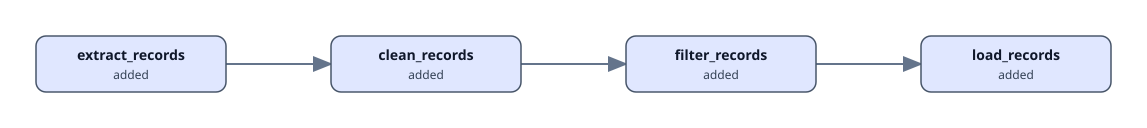

In [25]:
@task(name="extract_records")
def extract_records() -> list[Batch]:
    source_records: list[Record] = [
        {"name": " Ada ", "active": True},
        {"name": "Grace", "active": True},
        {"name": "Alan", "active": False},
    ]
    return list(InMemoryExtractor(source_records).extract(batch_size=2))

@task(name="clean_records", depends_on=("extract_records",))
def clean_records(batches: list[Batch]) -> list[Batch]:
    cleaner = CleanRecordsTransformer()
    return [cleaner.transform(batch) for batch in batches]

@task(name="filter_records", depends_on=("clean_records",))
def filter_records(batches: list[Batch]) -> list[Batch]:
    active_filter = FilterRecordsTransformer(
        lambda record: record["active"] is True,
    )
    return [active_filter.transform(batch) for batch in batches]

@task(name="load_records", depends_on=("filter_records",))
def load_records(batches: list[Batch]) -> list[Record]:
    selector = SelectColumnsTransformer(["name"])
    selected = [selector.transform(batch) for batch in batches]
    return ListLoader().load(selected)

pipeline = Pipeline()
# Dodajemy w odwrotnej kolejności, żeby pokazać, że graf steruje wykonaniem.
pipeline.add(load_records)
pipeline.add(filter_records)
pipeline.add(clean_records)
pipeline.add(extract_records)

show_pipeline_graph(pipeline)

INFO Starting task extract_records
INFO Finished task extract_records in 0.000 seconds
INFO Starting task clean_records
INFO Finished task clean_records in 0.000 seconds
INFO Starting task filter_records
INFO Finished task filter_records in 0.000 seconds
INFO Starting task load_records
INFO Finished task load_records in 0.000 seconds


Wyniki zadań: {'extract_records': [[{'name': ' Ada ', 'active': True}, {'name': 'Grace', 'active': True}], [{'name': 'Alan', 'active': False}]], 'clean_records': [[{'name': 'Ada', 'active': True}, {'name': 'Grace', 'active': True}], [{'name': 'Alan', 'active': False}]], 'filter_records': [[{'name': 'Ada', 'active': True}, {'name': 'Grace', 'active': True}], []], 'load_records': [{'name': 'Ada'}, {'name': 'Grace'}]}
Status pipeline: succeeded; czas: 0.007255 s
  extract_records: succeeded; czas=0.001213 s
  clean_records: succeeded; czas=0.001180 s
  filter_records: succeeded; czas=0.000855 s
  load_records: succeeded; czas=0.000479 s


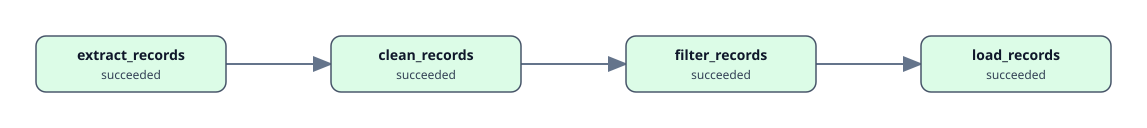

In [26]:
pipeline_results = pipeline.run()
print("Wyniki zadań:", pipeline_results)

report = pipeline.last_report
print(f"Status pipeline: {report.status}; czas: {report.duration_seconds:.6f} s")
for job_report in report.tasks:
    duration = job_report.duration_seconds
    print(f"  {job_report.name}: {job_report.status}; czas={duration:.6f} s")

show_pipeline_graph(pipeline)

## 6. Wykonanie asynchroniczne i równoległość

`await pipeline.run_async()` pozwala niezależnym **asynchronicznym** zadaniom działać współbieżnie. Zadanie zależne czeka na wszystkie swoje zależności i otrzymuje ich wyniki w kolejności z `depends_on`. Zadania synchroniczne są wykonywane inline w pętli zdarzeń, więc nie powinny zawierać blokującej pracy.

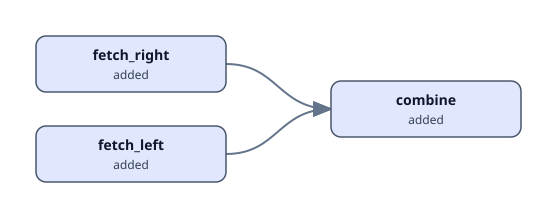

INFO Starting task fetch_right
INFO Starting task fetch_left


start fetch_right
start fetch_left


INFO Finished task fetch_right in 0.205 seconds
INFO Finished task fetch_left in 0.204 seconds
INFO Starting task combine
INFO Finished task combine in 0.000 seconds


done fetch_right
done fetch_left
combine startuje dopiero po obu fetch
Wynik: 42
Raport: PipelineReport(status='succeeded', duration_seconds=0.2090076999993471, tasks=(TaskReport(name='fetch_right', status='succeeded', duration_seconds=0.20582380000087142, error=None), TaskReport(name='fetch_left', status='succeeded', duration_seconds=0.2049840999989101, error=None), TaskReport(name='combine', status='succeeded', duration_seconds=0.0004760000010719523, error=None)))


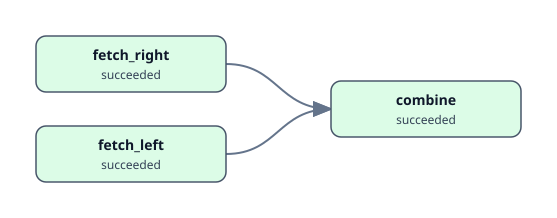

In [27]:
@task(name="fetch_left")
async def fetch_left() -> int:
    print("start fetch_left")
    await asyncio.sleep(0.2)
    print("done fetch_left")
    return 20

@task(name="fetch_right")
async def fetch_right() -> int:
    print("start fetch_right")
    await asyncio.sleep(0.2)
    print("done fetch_right")
    return 22

@task(name="combine", depends_on=("fetch_left", "fetch_right"))
async def combine(left: int, right: int) -> int:
    print("combine startuje dopiero po obu fetch")
    return left + right

async_pipeline = Pipeline()
async_pipeline.add(combine)
async_pipeline.add(fetch_right)
async_pipeline.add(fetch_left)

show_pipeline_graph(async_pipeline)
async_results = await async_pipeline.run_async()
print("Wynik:", async_results["combine"])
print("Raport:", async_pipeline.last_report)
show_pipeline_graph(async_pipeline)

### Błąd i statusy zależnych zadań

Jeśli zadanie zawiedzie, wyjątek jest przekazywany wywołującemu. Zadanie, które nie może wystartować z powodu nieudanego wymagania, otrzymuje status `skipped`. Poniżej przechwytujemy wyjątek, żeby można było kontynuować notebook.

INFO Starting task unstable
ERROR Task unstable failed
Traceback (most recent call last):
  File "C:\Users\Oliwier\Desktop\APP\src\workflow_engine\pipeline.py", line 177, in execute
    result = await self._execute_async_job(job, *dependency_results)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Oliwier\Desktop\APP\src\workflow_engine\pipeline.py", line 232, in _execute_async_job
    result = job(*args)
  File "C:\Users\Oliwier\Desktop\APP\src\workflow_engine\tasks.py", line 55, in __call__
    return self.func(*args, **kwargs)
           ~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "C:\Users\Oliwier\AppData\Local\Temp\ipykernel_24256\3500436928.py", line 3, in unstable
    raise ValueError("przykładowy błąd zadania")
ValueError: przykładowy błąd zadania
WARNING Skipping task after_unstable because a dependency failed


Pipeline zgłosił: przykładowy błąd zadania
unstable: failed; błąd=ValueError: przykładowy błąd zadania
after_unstable: skipped; błąd=Dependency failed: ValueError: przykładowy błąd zadania


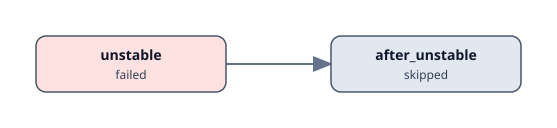

In [28]:
@task(name="unstable")
def unstable() -> None:
    raise ValueError("przykładowy błąd zadania")

@task(name="after_unstable", depends_on=("unstable",))
def after_unstable(_value: None) -> str:
    return "to się nie wykona"

failing_pipeline = Pipeline()
failing_pipeline.add(after_unstable)
failing_pipeline.add(unstable)

try:
    await failing_pipeline.run_async()
except ValueError as error:
    print(f"Pipeline zgłosił: {error}")

for job_report in failing_pipeline.last_report.tasks:
    print(f"{job_report.name}: {job_report.status}; błąd={job_report.error}")

show_pipeline_graph(failing_pipeline)

## 7. CLI i dalsze kroki

CLI uruchamia plik Python, który udostępnia funkcję `build_pipeline()` zwracającą `Pipeline`. Polecenie `run` wypisuje graf, logi oraz końcowe statusy i czasy; `graph` pokazuje same zależności bez uruchamiania zadań.

Z katalogu głównego repozytorium:

```powershell
uv run workflow-engine graph examples/cli_workflow.py
uv run workflow-engine run examples/cli_workflow.py
```

W pliku workflow należy zbudować pipeline, dodać zadania i zwrócić go z `build_pipeline()`. Przykład znajduje się w `examples/cli_workflow.py`.